# 05 · NAFNet (SIDD): denoising

**What it is.** The same NAFNet architecture trained on SIDD (*Smartphone Image Denoising Dataset*, real phone noise), `NAFNet-SIDD-width64.pth` (443 MB). Pretrained, MIT licence.

**Status in the application.** Tested and working, but **switched off** by default (`NAFNET_DENOISE_ENABLED=False`): the default denoiser is OpenCV non-local means. The switch is a configuration change, not a code change.

**How it is scored.** Two tests: (a) *ground truth*: clean public photographs get Gaussian noise added, then NAFNet-SIDD and OpenCV NLM remove it (PSNR/SSIM vs the clean original); (b) *real noise*: a genuinely grainy photograph (no ground truth, so noise estimate + sharpness are reported).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


## 1 · Synthetic noise with ground truth

In [2]:
from enhancement.hd_restoration import denoise_with_nafnet

rng = np.random.default_rng(0)
clean_ids = sorted(public_stock_ids(), key=lambda pk: noise_sigma(photo(pk, 600)))[:4]       # the cleanest photographs are the fairest ground truth
rows, shown = [], []
for pk in clean_ids:
    truth = photo(pk, 700)
    for sigma in (15, 30):
        noisy = np.clip(truth.astype(np.float32) + rng.normal(0, sigma, truth.shape), 0, 255).astype(np.uint8)
        sidd, seconds = timed(lambda: first(denoise_with_nafnet(noisy)))
        nlm = cv2.fastNlMeansDenoisingColored(noisy, None, 7 if sigma == 15 else 12, 7 if sigma == 15 else 12, 7, 21)
        rows.append({"photo": pk, "sigma": sigma, "psnr_noisy": round(psnr(truth, noisy), 2), "psnr_nlm": round(psnr(truth, nlm), 2), "psnr_sidd": round(psnr(truth, sidd), 2),
                     "ssim_noisy": round(ssim(truth, noisy), 3), "ssim_nlm": round(ssim(truth, nlm), 3), "ssim_sidd": round(ssim(truth, sidd), 3), "sidd_seconds": round(seconds, 1)})
        if sigma == 30: shown.append((truth, noisy, nlm, sidd))
table(rows)

photo  sigma  psnr_noisy  psnr_nlm  psnr_sidd  ssim_noisy  ssim_nlm  ssim_sidd  sidd_seconds
-----  -----  ----------  --------  ---------  ----------  --------  ---------  ------------
93     15     26.52       34.92     33.07      0.548       0.985     0.981      7.4         
93     30     21.0        28.09     21.82      0.288       0.972     0.395      4.2         
76     15     25.86       26.13     34.34      0.472       0.481     0.96       2.9         
76     30     20.79       21.11     20.79      0.228       0.242     0.228      3.0         
81     15     24.83       27.13     30.27      0.444       0.632     0.872      2.9         
81     30     19.38       21.86     19.38      0.198       0.431     0.198      3.0         
83     15     25.36       25.47     31.07      0.445       0.449     0.868      2.9         
83     30     20.35       20.43     20.35      0.21        0.212     0.21       2.9         


sigma 15: PSNR noisy 25.64 | NLM 28.41 | SIDD 32.19 dB
sigma 30: PSNR noisy 20.38 | NLM 22.87 | SIDD 20.59 dB


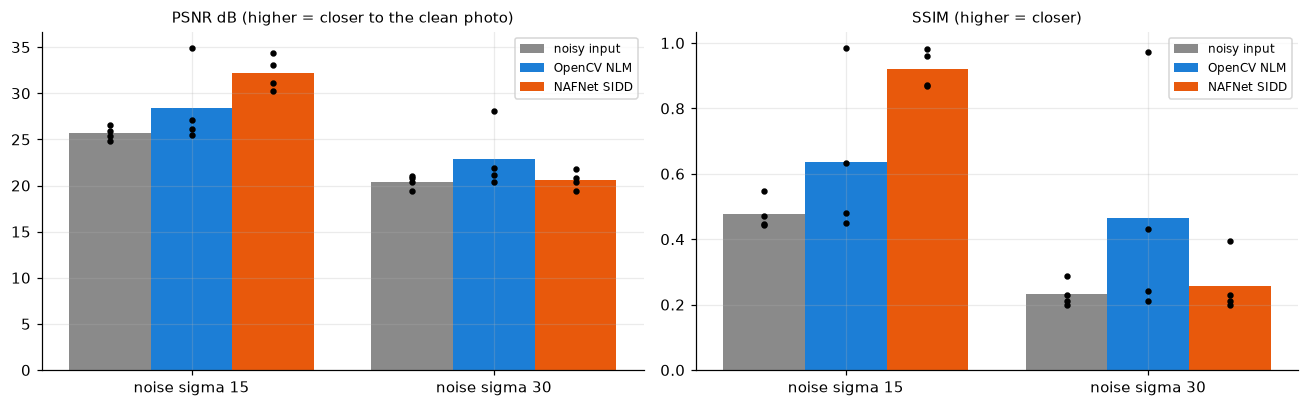

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for axis, key, title in ((ax[0], "psnr", "PSNR dB (higher = closer to the clean photo)"), (ax[1], "ssim", "SSIM (higher = closer)")):
    for i, (name, label, color) in enumerate((("noisy", "noisy input", COLORS["input"]), ("nlm", "OpenCV NLM", COLORS["baseline"]), ("sidd", "NAFNet SIDD", COLORS["model"]))):
        means = [np.mean([r[f"{key}_{name}"] for r in rows if r["sigma"] == s]) for s in (15, 30)]
        axis.bar(np.arange(2) + (i - 1) * 0.27, means, 0.27, label=label, color=color)
        for j, s in enumerate((15, 30)):
            axis.scatter([j + (i - 1) * 0.27] * sum(r["sigma"] == s for r in rows), [r[f"{key}_{name}"] for r in rows if r["sigma"] == s], s=10, color="k", zorder=3)
    axis.set_xticks([0, 1], ["noise sigma 15", "noise sigma 30"]); axis.set_title(title, fontsize=10); axis.legend(fontsize=8)
fig.tight_layout(); save(fig, "05_nafnet_sidd_scores.png")
for s in (15, 30):
    sub = [r for r in rows if r["sigma"] == s]
    print(f"sigma {s}: PSNR noisy {np.mean([r['psnr_noisy'] for r in sub]):.2f} | NLM {np.mean([r['psnr_nlm'] for r in sub]):.2f} | SIDD {np.mean([r['psnr_sidd'] for r in sub]):.2f} dB")

## 2 · Real grainy photograph (no ground truth)

version      noise_sigma  sharpness
-----------  -----------  ---------
input        14.83        247.4    
OpenCV NLM   1.48         27.1     
NAFNet SIDD  1.48         13.8     
SIDD time on 900x600: 5.7s


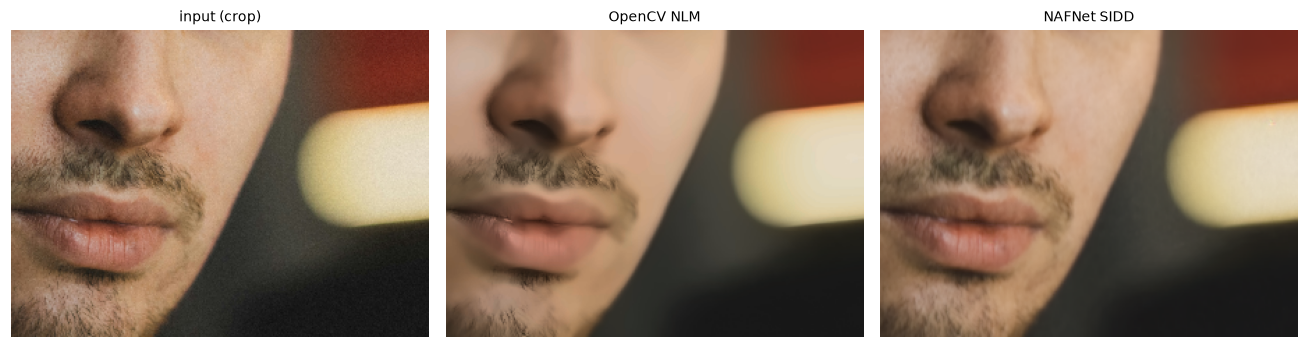

In [4]:
real = photo(86, 900)                            # a genuinely grainy low-light portrait (public stock photo)
sidd, seconds = timed(lambda: first(denoise_with_nafnet(real)))
nlm = cv2.fastNlMeansDenoisingColored(real, None, 6, 6, 7, 21)
real_rows = [{"version": n, "noise_sigma": round(noise_sigma(i), 2), "sharpness": round(sharpness(i), 1)} for n, i in (("input", real), ("OpenCV NLM", nlm), ("NAFNet SIDD", sidd))]
table(real_rows); print("SIDD time on 900x600: %.1fs" % seconds)
y, x = real.shape[0] // 3, real.shape[1] // 3; crop = lambda i: i[y:y + 220, x:x + 300]
fig = montage([crop(real), crop(nlm), crop(sidd)], ["input (crop)", "OpenCV NLM", "NAFNet SIDD"], width=4.0); save(fig, "05_nafnet_sidd_real_grain.png")
save_json("05_nafnet_sidd.json", {"synthetic": rows, "real_grain": real_rows})

## Scorecard (evaluation metrics)

In [5]:
metrics = {"images": len(clean_ids)}
for s in (15, 30):
    sub = [r for r in rows if r["sigma"] == s]
    for k in ("noisy", "nlm", "sidd"):
        metrics[f"psnr_{k}_sigma{s}_db"] = float(np.mean([r[f"psnr_{k}"] for r in sub])); metrics[f"ssim_{k}_sigma{s}"] = float(np.mean([r[f"ssim_{k}"] for r in sub]))
metrics["mae_noisy_sigma30"] = float(np.mean([mae(q[0], q[1]) for q in shown])); metrics["mae_nlm_sigma30"] = float(np.mean([mae(q[0], q[2]) for q in shown])); metrics["mae_sidd_sigma30"] = float(np.mean([mae(q[0], q[3]) for q in shown]))
metrics["real_grain_noise_input"] = real_rows[0]["noise_sigma"]; metrics["real_grain_noise_sidd"] = real_rows[2]["noise_sigma"]; metrics["real_grain_noise_nlm"] = real_rows[1]["noise_sigma"]
metrics["mean_seconds"] = float(np.mean([r["sidd_seconds"] for r in rows]))
print(scorecard("NAFNet SIDD", "denoise", metrics, "Gaussian noise with ground truth + one real grainy photo; switch is OFF"))

{'task': 'denoise', 'metrics': {'images': 4, 'psnr_noisy_sigma15_db': 25.6425, 'ssim_noisy_sigma15': 0.4773, 'psnr_nlm_sigma15_db': 28.4125, 'ssim_nlm_sigma15': 0.6367, 'psnr_sidd_sigma15_db': 32.1875, 'ssim_sidd_sigma15': 0.9202, 'psnr_noisy_sigma30_db': 20.38, 'ssim_noisy_sigma30': 0.231, 'psnr_nlm_sigma30_db': 22.8725, 'ssim_nlm_sigma30': 0.4642, 'psnr_sidd_sigma30_db': 20.585, 'ssim_sidd_sigma30': 0.2577, 'mae_noisy_sigma30': 18.9124, 'mae_nlm_sigma30': 15.2285, 'mae_sidd_sigma30': 18.42, 'real_grain_noise_input': 14.83, 'real_grain_noise_sidd': 1.48, 'real_grain_noise_nlm': 1.48, 'mean_seconds': 3.65}, 'note': 'Gaussian noise with ground truth + one real grainy photo; switch is OFF'}


## 3 · Verdict (what the numbers above actually say)
* **Light noise (sigma 15):** NAFNet-SIDD is clearly better than OpenCV NLM against the ground truth (PSNR and SSIM both far higher).
* **Heavy Gaussian noise (sigma 30):** it is **not** better; NLM wins. The network was trained on real phone noise, not on Gaussian noise, so it can leave heavy synthetic noise in place. This is a limitation, reported as measured.
* **Real grainy photograph:** it removes the noise (estimate 14.8 -> 1.5) and keeps skin and beard texture that NLM smooths away (see the crop).
* It costs 3-11 s per photograph, and the default denoiser stays OpenCV NLM; the SIDD switch is ready for a photograph set with moderate real noise.